In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('loan_approval_data.csv')
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-null    object 
 16  Educati

In [4]:
df.describe()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000
mean,501.220000,10852.571579,5082.455789,39.971579,1.474737,676.033684,1.950526,0.347263,9940.452632,24802.792632,20522.825263,48.000000
std,289.608451,5061.632859,2943.161570,11.139797,1.105067,71.346015,1.406246,0.144341,5860.736885,14345.696031,11504.142575,24.245322
min,1.000000,2009.000000,1.000000,21.000000,0.000000,550.000000,0.000000,0.100000,65.000000,36.000000,1015.000000,12.000000
25%,250.250000,6730.750000,2472.750000,30.250000,1.000000,616.250000,1.000000,0.220000,4760.250000,12698.250000,9806.250000,24.000000
50%,499.500000,10548.000000,5205.500000,40.000000,1.000000,678.000000,2.000000,0.340000,9880.500000,24321.000000,21210.500000,48.000000
75%,752.750000,15190.000000,7620.750000,49.000000,2.000000,737.000000,3.000000,0.480000,15074.500000,36947.000000,30263.000000,72.000000
max,1000.000000,19988.000000,9996.000000,59.000000,3.000000,799.000000,4.000000,0.600000,19996.000000,49954.000000,39995.000000,84.000000


In [5]:
# Check missing values
df.isnull().sum()

Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

In [6]:
df.isnull().sum().sum()

np.int64(1000)

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
# Target Variable distribution

df['Loan_Approved'].value_counts()

Loan_Approved
No     652
Yes    298
Name: count, dtype: int64

In [9]:
df['Loan_Approved'].value_counts(normalize = True) * 100

Loan_Approved
No     68.631579
Yes    31.368421
Name: proportion, dtype: float64

In [10]:
# Numericak and Categorical columns

numerical_cols = df.select_dtypes(include = ['int64', 'float64']).columns
numerical_cols

Index(['Applicant_ID', 'Applicant_Income', 'Coapplicant_Income', 'Age',
       'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings',
       'Collateral_Value', 'Loan_Amount', 'Loan_Term'],
      dtype='object')

In [11]:
categorical_cols = df.select_dtypes(include = ['object']).columns
categorical_cols

Index(['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area',
       'Education_Level', 'Gender', 'Employer_Category', 'Loan_Approved'],
      dtype='object')

# EDA - Exploratory data analysis

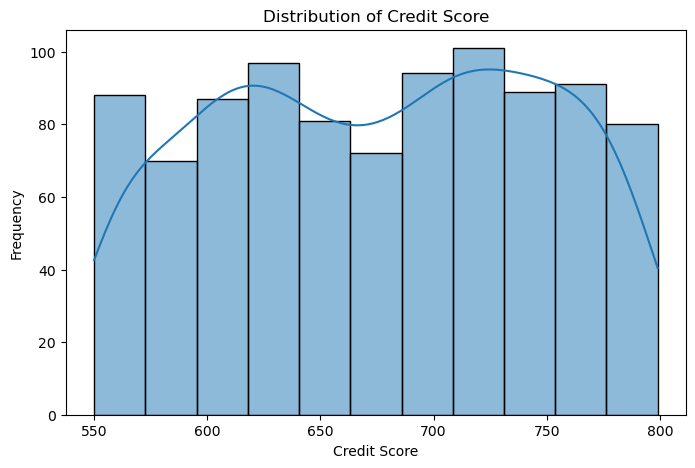

In [12]:
plt.figure(figsize = (8,5))

sns.histplot(data = df, x = 'Credit_Score', kde = True)
plt.title('Distribution of Credit Score')
plt.xlabel('Credit Score')
plt.ylabel('Frequency')

plt.show()

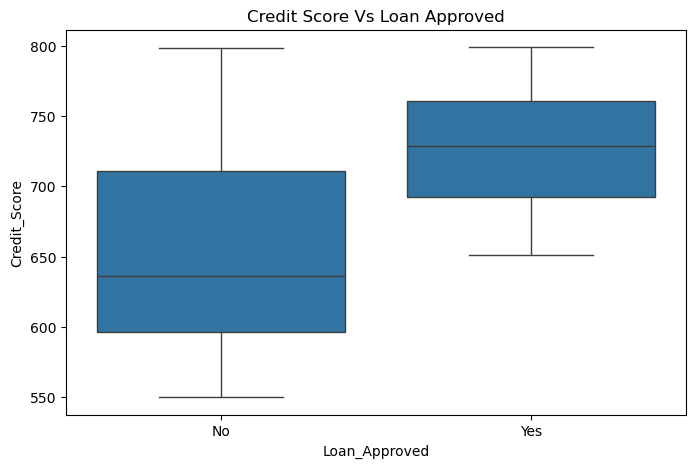

In [13]:
plt.figure(figsize = (8,5))

sns.boxplot(data = df, 
            x = 'Loan_Approved',
            y = 'Credit_Score')

plt.title('Credit Score Vs Loan Approved')
plt.show()

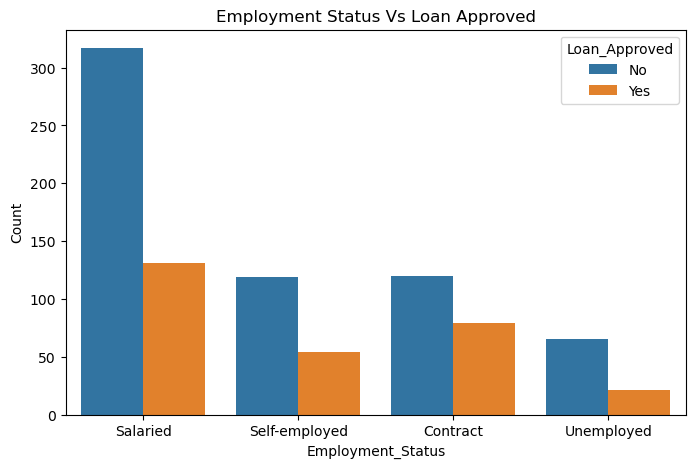

In [14]:
plt.figure(figsize = (8,5))

sns.countplot(data = df,
              x = 'Employment_Status',
              hue ='Loan_Approved')
plt.title('Employment Status Vs Loan Approved')
plt.xlabel('Employment_Status')
plt.ylabel('Count')

plt.show()

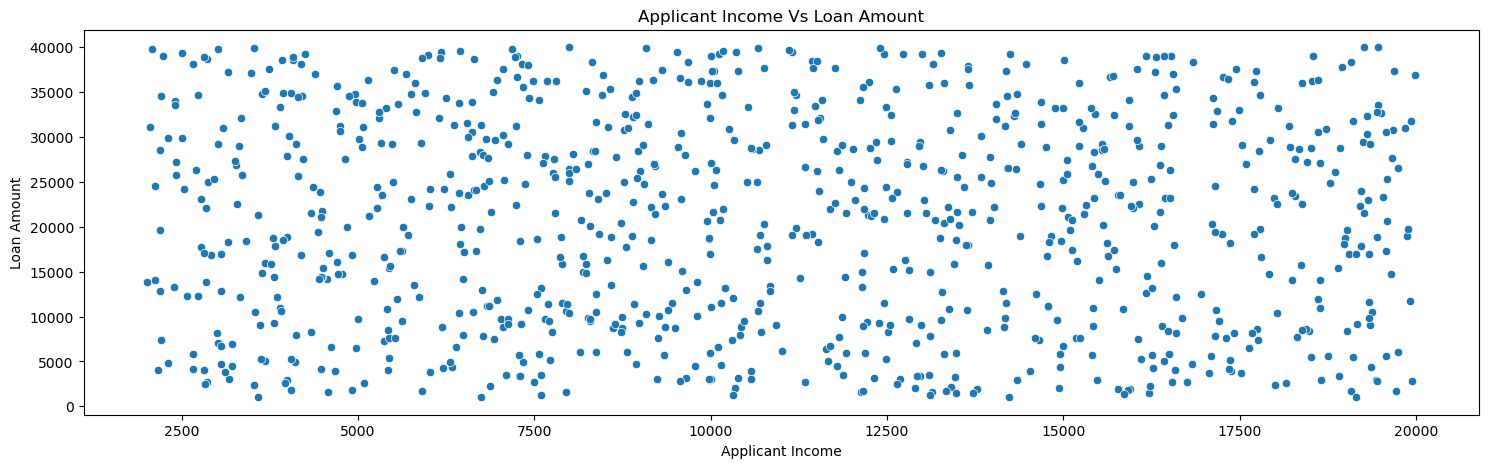

In [15]:
plt.figure(figsize = (18,5))

sns.scatterplot(data = df,
                x = 'Applicant_Income',
                y = 'Loan_Amount')

plt.title('Applicant Income Vs Loan Amount')
plt.xlabel('Applicant Income')
plt.ylabel('Loan Amount')

plt.show()


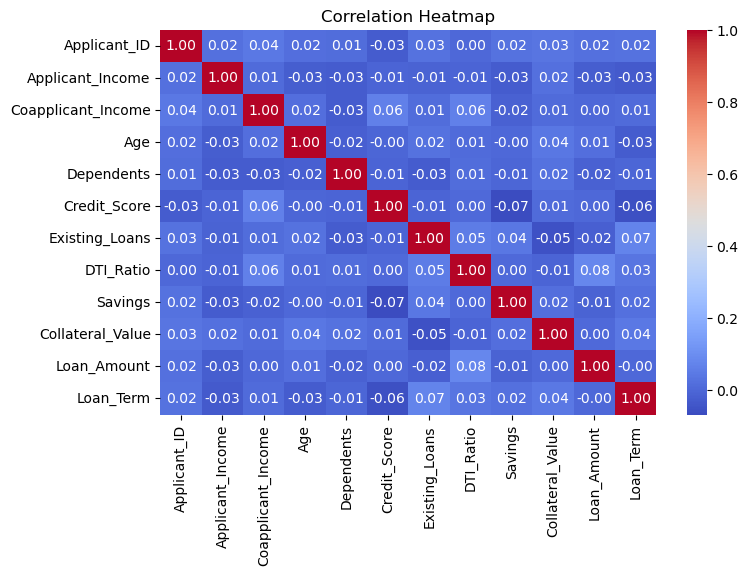

In [16]:
plt.figure(figsize = (8,5))

sns.heatmap(

df.select_dtypes(include =np.number).corr(),
    annot = True,
    cmap = 'coolwarm',
    fmt = '.2f'
)

plt.title('Correlation Heatmap')
plt.show()

# Data Cleaning

In [17]:
df.isnull().sum()

Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

In [18]:
missing_percentage = (df.isnull().sum()/ len(df)) * 100
missing_percentage

Applicant_ID          5.0
Applicant_Income      5.0
Coapplicant_Income    5.0
Employment_Status     5.0
Age                   5.0
Marital_Status        5.0
Dependents            5.0
Credit_Score          5.0
Existing_Loans        5.0
DTI_Ratio             5.0
Savings               5.0
Collateral_Value      5.0
Loan_Amount           5.0
Loan_Term             5.0
Loan_Purpose          5.0
Property_Area         5.0
Education_Level       5.0
Gender                5.0
Employer_Category     5.0
Loan_Approved         5.0
dtype: float64

In [19]:
df['Loan_Approved'].isnull().sum()

np.int64(50)

In [20]:
df.dtypes

Applicant_ID          float64
Applicant_Income      float64
Coapplicant_Income    float64
Employment_Status      object
Age                   float64
Marital_Status         object
Dependents            float64
Credit_Score          float64
Existing_Loans        float64
DTI_Ratio             float64
Savings               float64
Collateral_Value      float64
Loan_Amount           float64
Loan_Term             float64
Loan_Purpose           object
Property_Area          object
Education_Level        object
Gender                 object
Employer_Category      object
Loan_Approved          object
dtype: object

In [21]:
# remove missing target values

df = df.dropna(subset=['Loan_Approved'])
df.shape

(950, 20)

In [22]:
df = df.drop('Applicant_ID', axis = 1)

In [23]:
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [24]:
df['Loan_Approved'].value_counts()

Loan_Approved
No     652
Yes    298
Name: count, dtype: int64

In [25]:
# Separate features and target

X = df.drop('Loan_Approved', axis =1)
y = df['Loan_Approved']


In [26]:
# Train-Test-Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42, stratify = y)

In [29]:

num_cols = X_train.select_dtypes(include = ['int64', 'float64']).columns

cat_cols = X_train.select_dtypes(include = ['object']).columns

In [30]:
from sklearn.impute import SimpleImputer

num_imputer = SimpleImputer(strategy='median')

cat_imputer = SimpleImputer(strategy='most_frequent')

X_train[num_cols] = num_imputer.fit_transform(X_train[num_cols])

X_test[num_cols] = num_imputer.transform(X_test[num_cols])

X_train[cat_cols] = cat_imputer.fit_transform(X_train[cat_cols])

X_test[cat_cols] = cat_imputer.transform(X_test[cat_cols])

In [31]:
X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first = True, dtype = int)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first = True, dtype = int)

In [32]:
X_test = X_test.reindex(columns = X_train.columns, fill_value = 0)

In [33]:
#  encoding

num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')

In [34]:
# feature scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [35]:
# Model Training

from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=100)
lr_model.fit(X_train_scaled, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [36]:
lr_pred = lr_model.predict(X_test_scaled)

In [37]:
# evaluation 

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, lr_pred))
print("/nClassification Report:", classification_report(y_test, lr_pred))

Accuracy: 0.8894736842105263
/nClassification Report:               precision    recall  f1-score   support

          No       0.90      0.94      0.92       130
         Yes       0.85      0.78      0.82        60

    accuracy                           0.89       190
   macro avg       0.88      0.86      0.87       190
weighted avg       0.89      0.89      0.89       190



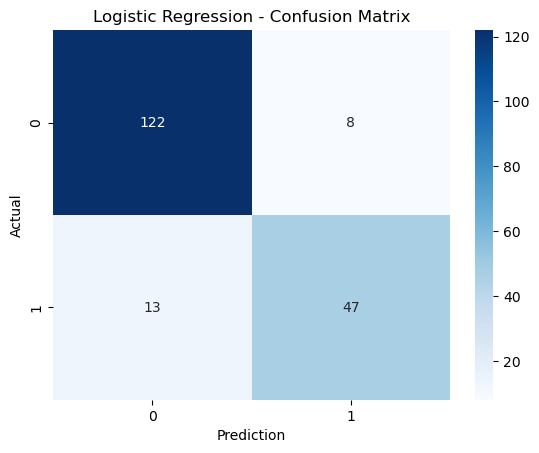

In [38]:
# confusion matrix

cm = confusion_matrix(y_test, lr_pred)

sns.heatmap(cm, annot=True,fmt='d',cmap='Blues')

plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.title('Logistic Regression - Confusion Matrix')

plt.show()

In [39]:
# Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier

dt_model =  DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [40]:
dt_pred = dt_model.predict(X_test)

In [41]:
# Evaluation

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, dt_pred))
print("/nClassification Report:", classification_report(y_test, dt_pred))

Accuracy: 0.9421052631578948
/nClassification Report:               precision    recall  f1-score   support

          No       0.95      0.96      0.96       130
         Yes       0.92      0.90      0.91        60

    accuracy                           0.94       190
   macro avg       0.93      0.93      0.93       190
weighted avg       0.94      0.94      0.94       190



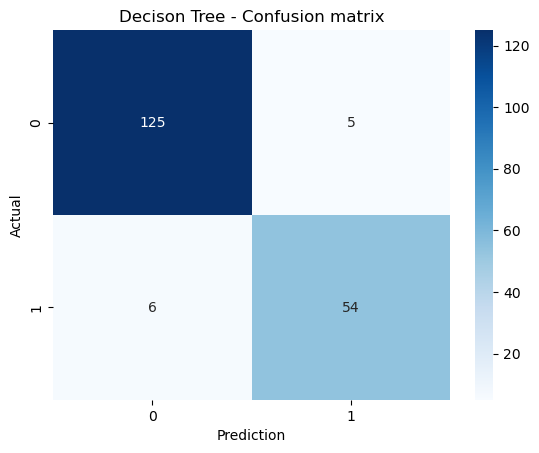

In [43]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, dt_pred)

sns.heatmap(cm,
            annot = True,
            fmt = 'd',
            cmap = 'Blues'
           )
plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.title('Decison Tree - Confusion matrix')

plt.show()

In [44]:
# Random Forest

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=42)

rf_model.fit(X_train, y_train)


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [45]:
rf_pred = rf_model.predict(X_test)

In [51]:
# Evaluation

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("\nClassification Report:", (y_test, rf_pred))

Accuracy: 0.9526315789473684

Classification Report: (153    Yes
664    Yes
376     No
890    Yes
589    Yes
      ... 
523     No
227    Yes
21      No
330     No
657     No
Name: Loan_Approved, Length: 190, dtype: object, array(['Yes', 'Yes', 'No', 'Yes', 'Yes', 'No', 'Yes', 'Yes', 'No', 'Yes',
       'No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'Yes', 'No', 'No', 'No',
       'No', 'No', 'No', 'No', 'Yes', 'No', 'Yes', 'Yes', 'No', 'No',
       'No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'Yes', 'No', 'No', 'No',
       'No', 'Yes', 'No', 'No', 'No', 'No', 'Yes', 'No', 'Yes', 'Yes',
       'No', 'No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'Yes', 'No', 'No',
       'No', 'No', 'No', 'No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'No',
       'No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'Yes', 'No', 'No', 'No',
       'No', 'Yes', 'Yes', 'No', 'No', 'No', 'Yes', 'Yes', 'No', 'No',
       'Yes', 'Yes', 'No', 'No', 'No', 'Yes', 'Yes', 'No', 'No', 'No',
       'No', 'Yes', 'No', 'No', 'No', 'No', 'No',

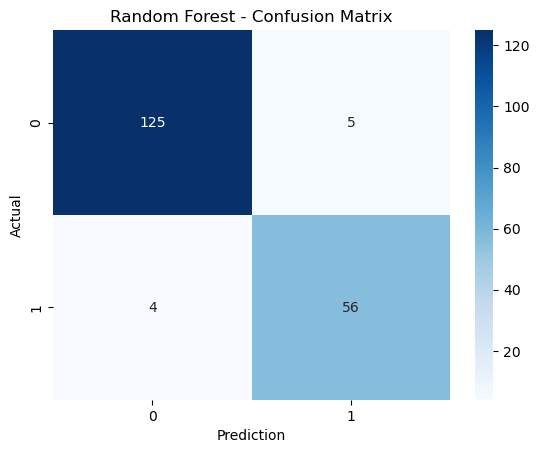

In [52]:
cm = confusion_matrix(y_test, rf_pred)

sns.heatmap(cm,
            annot = True,
            fmt = 'd',
            cmap = 'Blues'
                     )
plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.title('Random Forest - Confusion Matrix')

plt.show()


In [54]:
# Gradient Boosting

from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(random_state=42)

gb_model.fit(X_train, y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [55]:
gb_pred = gb_model.predict(X_test)

In [56]:
# Evaluation
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, gb_pred))
print("\nClassification Report:", (y_test, gb_pred))

Accuracy: 0.9631578947368421

Classification Report: (153    Yes
664    Yes
376     No
890    Yes
589    Yes
      ... 
523     No
227    Yes
21      No
330     No
657     No
Name: Loan_Approved, Length: 190, dtype: object, array(['Yes', 'Yes', 'No', 'Yes', 'Yes', 'No', 'Yes', 'Yes', 'No', 'Yes',
       'No', 'Yes', 'No', 'Yes', 'No', 'No', 'No', 'Yes', 'No', 'No',
       'No', 'No', 'No', 'No', 'No', 'Yes', 'No', 'Yes', 'Yes', 'No',
       'No', 'No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'Yes', 'No', 'No',
       'No', 'No', 'Yes', 'No', 'No', 'No', 'No', 'Yes', 'No', 'Yes',
       'Yes', 'No', 'No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'Yes',
       'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'Yes', 'Yes',
       'No', 'No', 'No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'Yes', 'No',
       'No', 'No', 'No', 'Yes', 'Yes', 'No', 'No', 'Yes', 'Yes', 'Yes',
       'No', 'No', 'Yes', 'Yes', 'No', 'No', 'No', 'Yes', 'Yes', 'No',
       'No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'No', 'No

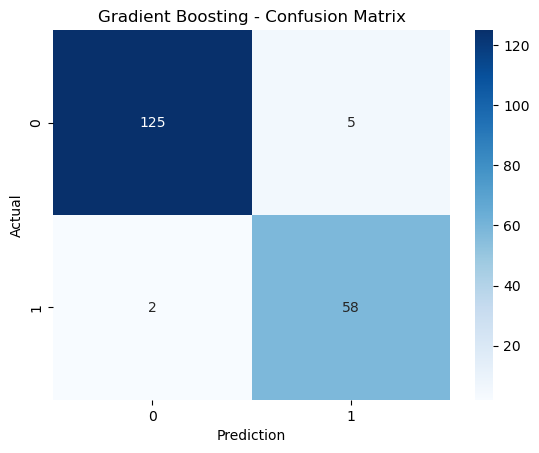

In [58]:
cm = confusion_matrix(y_test, gb_pred)

sns.heatmap(cm,
            annot = True,
            fmt = 'd',
            cmap = 'Blues'
                     )
plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.title('Gradient Boosting - Confusion Matrix')

plt.show()


In [61]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": lr_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "Gradient Boosting": gb_pred
}
results = []

for name, pred in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, pos_label="Yes"),
        "Recall": recall_score(y_test, pred, pos_label="Yes"),
        "F1 Score": f1_score(y_test, pred, pos_label="Yes")
    })

results_df = pd.DataFrame(results)
results_df       
        
    

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.889474,0.854545,0.783333,0.817391
1,Decision Tree,0.942105,0.915254,0.900000,0.907563
2,Random Forest,0.952632,0.918033,0.933333,0.925620
3,Gradient Boosting,0.963158,0.920635,0.966667,0.943089


In [ ]:
Loan Approval Prediction – Conclusion

In this project, I developed a machine learning classification model to predict whether a loan application would be approved or rejected based on applicant information.

I performed data preprocessing, handled missing values, encoded categorical variables, and split the dataset into training and testing sets. I trained and evaluated four machine learning models: Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting.

After comparing the models using Accuracy, Precision, Recall, and F1 Score, Gradient Boosting performed the best, achieving an accuracy of 96.32% and an F1 Score of 94.31%.

This project helped me understand the complete machine learning workflow, from data preprocessing and model training to evaluation and comparison.